# Notebook 05: Nested Dataset Subsets

The full dataset has 15.47M interactions, which is too large to train four models
across multiple seeds and two feature settings on a single GPU. This notebook builds
smaller nested versions of it.

The subsets are built by sampling users, then re-applying 5-core filtering, then
re-encoding the indices. Because the user samples are taken as prefixes of a single
shuffled permutation, the resulting graphs are strictly nested: small ⊆ medium ⊆ full.
This follows from the k-core being the unique maximal subgraph satisfying the degree
condition, so if H ⊆ G then core(H) ⊆ core(G).

The smallest subset is what the main model comparison will use. All three together
give the scalability experiment something to measure.

Input comes from Notebook 03 (encoded interactions) and the split statistics from
Notebook 04 are used as the reference for the `full` level.

## 1. Imports and configuration


In [ ]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import splitting as sp

# Paths
ENCODED_DIR = PROJECT_ROOT / "data" / "processed" / "encoded_earliest"
INTERACTIONS_PATH = ENCODED_DIR / "interactions_encoded.parquet"

SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
FULL_SPLITS_DIR = PROJECT_ROOT / "data" / "processed" / "splits_earliest"
FIGURES_DIR = PROJECT_ROOT / "figures"

SUBSETS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


SEED = 42
K_CORE = 5
N_EVAL_USERS = 50_000

# Fractions to try in the calibration step (Section 3).
CALIBRATION_FRACTIONS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

# Sampling fractions are configured here.
# Target for "small" is roughly 2-3M interactions, which is the range LightGCN and
# NGCF were originally evaluated on (Amazon-Book is 2.98M).
SUBSET_FRACTIONS = {
    "small": 0.20,    
    "medium": 0.45,   
    "full": 1.00,     
}

# Full-dataset values carried over from Notebook 03/04.
EXPECTED_INTERACTIONS = 15_473_536
EXPECTED_USERS = 1_641_026
EXPECTED_ITEMS = 368_228

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print(f"Project root : {PROJECT_ROOT}")
print(f"Subset output: {SUBSETS_DIR}")
print(f"Seed {SEED}, k-core {K_CORE}, {N_EVAL_USERS:,} evaluation users per subset")

Project root : c:\Projects\gnn-recommender-dissertation
Subset output: c:\Projects\gnn-recommender-dissertation\data\processed\subsets_earliest
Seed 42, k-core 5, 50,000 evaluation users per subset


## 2. Load the Full Dataset

Load the processed interaction dataset produced in Notebook 04. The index and rating
columns are stored as 32-bit integers to reduce memory usage, while the remaining
columns retain their original types.

Before creating any subsets, verify that the dataset statistics match the expected
values from the preprocessing stage.

In [2]:
start = time.time()
interactions = pq.read_table(INTERACTIONS_PATH).to_pandas()
interactions = interactions.astype({
    "user_idx": "int32",
    "item_idx": "int32",
    "rating": "float32",
})

n_interactions = len(interactions)
n_users = interactions["user_idx"].nunique()
n_items = interactions["item_idx"].nunique()

print(f"loaded in {time.time() - start:.1f}s")
print(f"{n_interactions:,} interactions | {n_users:,} users | {n_items:,} items")
print(f"memory: {interactions.memory_usage(deep=True).sum() / 1e9:.2f} GB")

assert n_interactions == EXPECTED_INTERACTIONS
assert n_users == EXPECTED_USERS
assert n_items == EXPECTED_ITEMS

interactions.head()

loaded in 0.6s
15,473,536 interactions | 1,641,026 users | 368,228 items
memory: 0.32 GB


,user_idx,item_idx,rating,timestamp,verified_purchase
0,19,19482,5.0,1376400100000,True
1,21,250434,4.0,1466627798000,True
2,57,67363,3.0,1430433320000,True
3,109,214426,5.0,1618659031257,True
4,148,31656,5.0,1374598326000,True


## 3. How Much Does 5-Core Filtering Shrink a Sample?

Sampling a fixed percentage of users does not produce the same percentage of
interactions. As low-degree users and items are removed during iterative 5-core
filtering, the dataset shrinks further than the initial sample.

This section measures the relationship between the sampled user fraction and the
final number of interactions after 5-core filtering. The results are then used to
select sampling fractions that produce subsets of the desired size. The target for
the smallest subset is approximately 2–3 million interactions, similar to the
scale used in the original LightGCN and NGCF evaluations on Amazon-Book.

As a consistency check, the implementation in `src/subsets.py` is also verified
against the preprocessing performed in Notebook 03. Since the full dataset already
satisfies the 5-core constraint, applying the filter again should leave it unchanged.

In [3]:
from src import subsets as sub

_, info = sub.iterative_k_core(interactions[["user_idx", "item_idx"]], k=K_CORE)
print(f"full dataset: {info['rows_in']:,} -> {info['rows_out']:,} rows "
      f"in {info['iterations']} iteration(s)")
assert info["rows_out"] == n_interactions, "full dataset is not 5-core"

full dataset: 15,473,536 -> 15,473,536 rows in 1 iteration(s)


In [4]:
calibration_samples = sub.nested_user_samples(
    interactions["user_idx"].to_numpy(),
    {f"{f:.0%}": f for f in CALIBRATION_FRACTIONS},
    seed=SEED,
)

# user_idx is contiguous, so a boolean lookup array is a lot faster than isin()
def select_users(df, user_ids):
    mask = np.zeros(n_users, dtype=bool)
    mask[user_ids] = True
    return df[mask[df["user_idx"].to_numpy()]]

rows = []
for name, user_ids in calibration_samples.items():
    t0 = time.time()
    cored, info = sub.iterative_k_core(select_users(interactions, user_ids), k=K_CORE)
    stats = sub.subset_statistics(cored)
    rows.append({
        "fraction": name,
        "users_sampled": len(user_ids),
        **stats,
        "iterations": info["iterations"],
    })
    print(f"{name:>4}  {stats['interactions']:>10,} interactions  "
          f"{stats['users']:>9,} users  {stats['items']:>8,} items   ({time.time()-t0:.0f}s)")

calibration = pd.DataFrame(rows)
calibration

  5%     323,654 interactions     38,348 users    21,680 items   (0s)
 10%     928,276 interactions    105,604 users    51,329 items   (1s)
 15%   1,611,579 interactions    180,054 users    79,021 items   (1s)
 20%   2,346,776 interactions    258,597 users   105,298 items   (1s)
 25%   3,109,980 interactions    339,681 users   129,815 items   (2s)
 30%   3,894,108 interactions    422,553 users   152,813 items   (2s)


,fraction,users_sampled,interactions,users,items,density,mean_user_degree,mean_item_degree,iterations
0,5%,82051,323654,38348,21680,0.000389,8.439919,14.928690,14
1,10%,164103,928276,105604,51329,0.000171,8.790159,18.084825,15
2,15%,246154,1611579,180054,79021,0.000113,8.950532,20.394313,14
3,20%,328205,2346776,258597,105298,0.000086,9.075032,22.286995,12
4,25%,410256,3109980,339681,129815,0.000071,9.155590,23.957016,13
5,30%,492308,3894108,422553,152813,0.000060,9.215668,25.482832,11


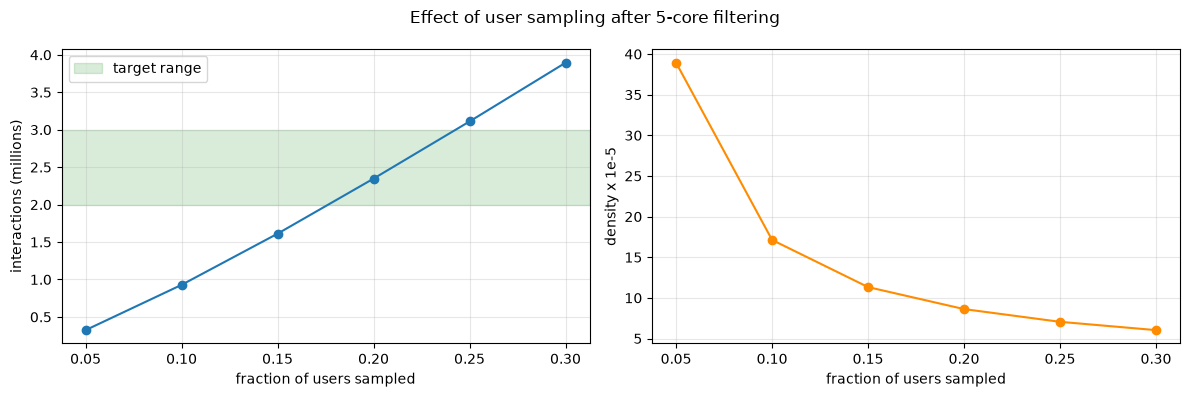

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x = [f / 100 for f in [int(s.rstrip('%')) for s in calibration["fraction"]]]

axes[0].plot(x, calibration["interactions"] / 1e6, "o-")
axes[0].axhspan(2, 3, alpha=0.15, color="green", label="target range")
axes[0].set_xlabel("fraction of users sampled")
axes[0].set_ylabel("interactions (millions)")
axes[0].legend()

axes[1].plot(x, calibration["density"] * 1e5, "o-", color="darkorange")
axes[1].set_xlabel("fraction of users sampled")
axes[1].set_ylabel("density x 1e-5")

for ax in axes:
    ax.grid(alpha=0.3)

fig.suptitle("Effect of user sampling after 5-core filtering")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Build the subsets

Same three steps for each level: take the user prefix, drop everything outside it,
re-run 5-core, then renumber to contiguous indices.

The samples come from one permutation so each is contained in the next. That's what
makes the subsets nested, and it's checked in Section 6.

`full` goes through the same code path even though nothing gets removed. It keeps the
output structure identical across levels, so later notebooks don't need a special case
for it.

In [7]:
subset_samples = sub.nested_user_samples(
    interactions["user_idx"].to_numpy(),
    SUBSET_FRACTIONS,
    seed=SEED,
)

subsets = {}
build_rows = []

for name, user_ids in subset_samples.items():
    t0 = time.time()

    sampled = select_users(interactions, user_ids)
    cored, info = sub.iterative_k_core(sampled, k=K_CORE)
    local, user_mapping, item_mapping = sub.reencode(cored)

    subsets[name] = {
        "interactions": local,
        "user_mapping": user_mapping,
        "item_mapping": item_mapping,
    }

    stats = sub.subset_statistics(local)
    build_rows.append({
        "subset": name,
        "fraction": SUBSET_FRACTIONS[name],
        "users_sampled": len(user_ids),
        "users_kept": stats["users"],
        **{k: v for k, v in stats.items() if k != "users"},
        "kcore_iterations": info["iterations"],
        "build_seconds": round(time.time() - t0, 1),
    })

    print(f"{name:>6}  {stats['interactions']:>10,} interactions  "
          f"{stats['users']:>9,} users  {stats['items']:>8,} items  "
          f"({info['iterations']} iters, {time.time()-t0:.0f}s)")

build_summary = pd.DataFrame(build_rows)
build_summary

 small   2,346,776 interactions    258,597 users   105,298 items  (12 iters, 2s)
medium   6,297,459 interactions    676,170 users   211,842 items  (13 iters, 5s)
  full  15,473,536 interactions  1,641,026 users   368,228 items  (1 iters, 4s)


,subset,fraction,users_sampled,users_kept,interactions,items,density,mean_user_degree,mean_item_degree,kcore_iterations,build_seconds
0,small,0.20,328205,258597,2346776,105298,0.000086,9.075032,22.286995,12,1.6
1,medium,0.45,738462,676170,6297459,211842,0.000044,9.313426,29.727150,13,4.7
2,full,1.00,1641026,1641026,15473536,368228,0.000026,9.429184,42.021617,1,4.4


In [8]:
# re-encoding is just a renumbering, so the 5-core property and the row count
# have to survive it
for name, data in subsets.items():
    df = data["interactions"]
    assert df["user_idx"].min() == 0
    assert df["item_idx"].min() == 0
    assert df["user_idx"].max() == len(data["user_mapping"]) - 1
    assert df["item_idx"].max() == len(data["item_mapping"]) - 1
    assert df.groupby("user_idx").size().min() >= K_CORE
    assert df.groupby("item_idx").size().min() >= K_CORE
    assert len(df.drop_duplicates(subset=["user_idx", "item_idx"])) == len(df)

print("all subsets: contiguous indices, 5-core holds, no duplicate pairs")

all subsets: contiguous indices, 5-core holds, no duplicate pairs


## 5. Comparing the Subsets

The table above reports the size of each subset. For the scalability study, it is
also useful to compare their structural properties.

Mean user degree remains relatively stable across the subsets because each sampled
user keeps their complete interaction history. In contrast, mean item degree
decreases more noticeably because each item loses interactions when users are
removed.

This difference is worth noting when interpreting the experimental results. If
model performance changes across the subsets, both the reduction in dataset size
and the change in the item degree distribution may contribute to the observed
differences.

In [10]:
comparison = build_summary.set_index("subset")[
    ["interactions", "users_kept", "items", "density", "mean_user_degree", "mean_item_degree"]
].rename(columns={"users_kept": "users"})

relative = (comparison / comparison.loc["full"]).add_suffix("_vs_full")

pd.concat(
    [comparison,
     relative[["interactions_vs_full", "users_vs_full", "items_vs_full",
               "mean_item_degree_vs_full"]]],
    axis=1,
)

,interactions,users,items,density,mean_user_degree,mean_item_degree,interactions_vs_full,users_vs_full,items_vs_full,mean_item_degree_vs_full
subset,,,,,,,,,,
small,2346776,258597,105298,0.000086,9.075032,22.286995,0.151664,0.157583,0.285959,0.530370
medium,6297459,676170,211842,0.000044,9.313426,29.727150,0.406983,0.412041,0.575301,0.707425
full,15473536,1641026,368228,0.000026,9.429184,42.021617,1.000000,1.000000,1.000000,1.000000


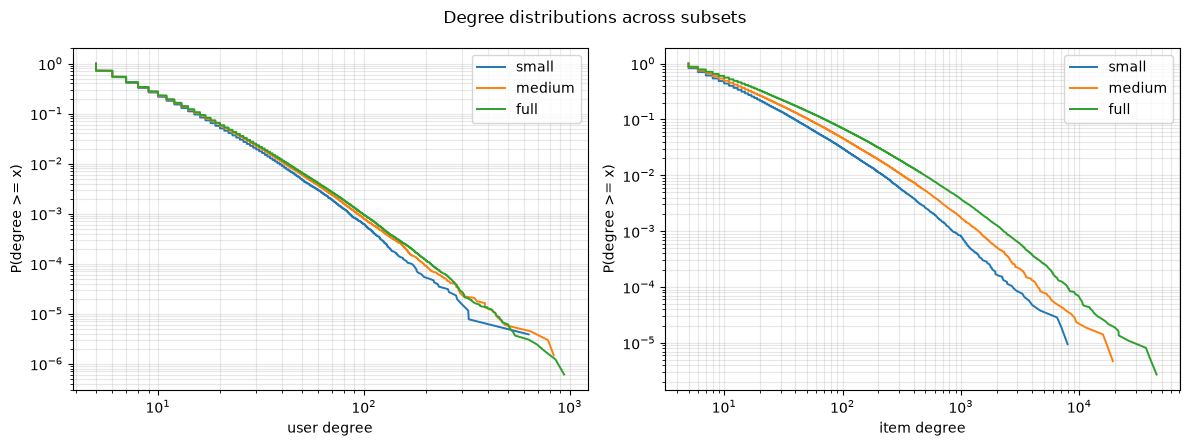

In [11]:
def ccdf(degrees):
    """Fraction of nodes with degree >= d, for plotting on log-log axes."""
    d = np.sort(degrees)
    return d, 1 - np.arange(len(d)) / len(d)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in ["small", "medium", "full"]:
    df = subsets[name]["interactions"]
    for ax, col in zip(axes, ["user_idx", "item_idx"]):
        d, y = ccdf(df.groupby(col).size().to_numpy())
        ax.loglog(d, y, label=name, linewidth=1.4)

axes[0].set_xlabel("user degree")
axes[1].set_xlabel("item degree")
for ax in axes:
    ax.set_ylabel("P(degree >= x)")
    ax.grid(alpha=0.3, which="both")
    ax.legend()

fig.suptitle("Degree distributions across subsets")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_degree_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Verifying Nested Subsets

The subsets are expected to satisfy the relationship

small ⊆ medium ⊆ full.

This property follows from constructing the user samples as nested prefixes of a
single random permutation before applying the iterative 5-core filtering.

The comparison is performed using the original global user and item indices, since
each subset is re-encoded independently after filtering.

In [12]:
def to_global(level):
    """Map a subset's local indices back to the global ones from Notebook 03."""
    data = subsets[level]
    df = data["interactions"]
    # mappings were built with arange, so row i holds the global id for local index i
    users = data["user_mapping"]["global_user_idx"].to_numpy()[df["user_idx"].to_numpy()]
    items = data["item_mapping"]["global_item_idx"].to_numpy()[df["item_idx"].to_numpy()]
    return users, items


def pack(users, items):
    return (users.astype(np.int64) << np.int64(32)) + items.astype(np.int64)


global_sets = {}
for name in ["small", "medium", "full"]:
    u, i = to_global(name)
    global_sets[name] = {
        "users": np.unique(u),
        "items": np.unique(i),
        "pairs": np.unique(pack(u, i)),
    }
    print(f"{name:>6}  {len(global_sets[name]['pairs']):>10,} pairs")

 small   2,346,776 pairs
medium   6,297,459 pairs
  full  15,473,536 pairs


In [13]:
rows = []
for inner, outer in [("small", "medium"), ("medium", "full"), ("small", "full")]:
    row = {"inner": inner, "outer": outer}
    for kind in ["users", "items", "pairs"]:
        a, b = global_sets[inner][kind], global_sets[outer][kind]
        row[f"{kind}_outside"] = int(np.setdiff1d(a, b, assume_unique=True).size)
        row[f"{kind}_coverage"] = round(len(a) / len(b), 4)
    rows.append(row)

nesting = pd.DataFrame(rows)
print(nesting.to_string(index=False))

for col in [c for c in nesting.columns if c.endswith("_outside")]:
    assert (nesting[col] == 0).all(), f"nesting broken: {col}"

print("\nsmall ⊆ medium ⊆ full holds for users, items and interactions")

 inner  outer  users_outside  users_coverage  items_outside  items_coverage  pairs_outside  pairs_coverage
 small medium              0          0.3824              0          0.4971              0          0.3727
medium   full              0          0.4120              0          0.5753              0          0.4070
 small   full              0          0.1576              0          0.2860              0          0.1517

small ⊆ medium ⊆ full holds for users, items and interactions


## 7. Split every subset

Same two protocols as Notebook 04, applied to each level. `src/splitting.py` does the
work, so the subsets are split by exactly the same code as the full dataset.

The timestamp cutoffs stay at their absolute values. They're fixed by the dataset authors, and rescaling them would mean each level
was evaluated over a different time window, which would confound the scaling comparison.

Six splits in total (3 subsets x 2 protocols), each verified the same way as before.

In [14]:
import gc

# subsets["full"] is an independent copy of the same data, so the original frame
# is just taking up memory now
del interactions
gc.collect()

3089

In [15]:
splits = {}
split_rows = []

for name in ["small", "medium", "full"]:
    df = subsets[name]["interactions"]
    n_sub_users = df["user_idx"].nunique()

    for protocol in ["last_out", "timestamp"]:
        t0 = time.time()
        if protocol == "last_out":
            result = sp.leave_last_out_split(df)
        else:
            result = sp.global_timestamp_split(df, sp.OFFICIAL_T1, sp.OFFICIAL_T2)

        splits[(name, protocol)] = result
        counts = result.counts

        split_rows.append({
            "subset": name,
            "protocol": protocol,
            **counts,
            "seconds": round(time.time() - t0, 1),
        })
        print(f"{name:>6} {protocol:>10}  "
              f"train {counts['train']:>10,}  "
              f"valid {counts['validation']:>9,}  "
              f"test {counts['test']:>9,}")

    # leave-last-out removes exactly two rows per user, so this has to hold
    llo = splits[(name, "last_out")].counts
    assert llo["train"] == len(df) - 2 * n_sub_users
    assert llo["validation"] == n_sub_users and llo["test"] == n_sub_users

split_summary = pd.DataFrame(split_rows)
split_summary

 small   last_out  train  1,829,582  valid   258,597  test   258,597
 small  timestamp  train  2,020,041  valid   165,504  test   161,231
medium   last_out  train  4,945,119  valid   676,170  test   676,170
medium  timestamp  train  5,358,564  valid   460,226  test   478,669
  full   last_out  train 12,191,484  valid 1,641,026  test 1,641,026
  full  timestamp  train 13,096,427  valid 1,161,644  test 1,215,465


,subset,protocol,train,validation,test,total,seconds
0,small,last_out,1829582,258597,258597,2346776,0.9
1,small,timestamp,2020041,165504,161231,2346776,0.9
2,medium,last_out,4945119,676170,676170,6297459,2.8
3,medium,timestamp,5358564,460226,478669,6297459,2.7
4,full,last_out,12191484,1641026,1641026,15473536,9.4
5,full,timestamp,13096427,1161644,1215465,15473536,9.1


In [16]:
for (name, protocol), result in splits.items():
    total = sum(result.counts[k] for k in ["train", "validation", "test"])

    assert sp.verify_partition(result, total)["is_exact_partition"]
    assert all(v == 0 for v in sp.verify_no_pair_overlap(result).values())

    timeline = sp.verify_local_timeline(result)
    assert all(v == 0 for k, v in timeline.items() if k.startswith("violations"))

    if protocol == "timestamp":
        bounds = sp.verify_global_boundaries(result, sp.OFFICIAL_T1, sp.OFFICIAL_T2)
        assert bounds["train_before_t1"]
        assert bounds["validation_within_bounds"]
        assert bounds["test_after_t2"]

print(f"all {len(splits)} splits verified")

all 6 splits verified


In [17]:
# does lookahead exposure change with dataset size, or is it purely a property of the protocol?
lookahead_rows = []
for (name, protocol), result in splits.items():
    lk = sp.quantify_lookahead(result.train, result.test)
    lookahead_rows.append({
        "subset": name,
        "protocol": protocol,
        "test_instances": lk["n_test_instances"],
        "share_affected": round(lk["share_of_test_instances_affected"], 6),
        "mean_share_of_training_set": round(lk["mean_share_of_training_set"], 4),
    })

pd.DataFrame(lookahead_rows)

,subset,protocol,test_instances,share_affected,mean_share_of_training_set
0,small,last_out,258597,0.999996,0.1841
1,small,timestamp,161231,0.000000,0.0000
2,medium,last_out,676170,0.999997,0.1888
3,medium,timestamp,478669,0.000000,0.0000
4,full,last_out,1641026,0.999998,0.1903
5,full,timestamp,1215465,0.000000,0.0000


## 8. Coverage and evaluation samples

Same three things as Notebook 04, now per subset and protocol:

- users with no training interactions (nothing can score them, so they're excluded)
- strictly cold items, which is the population the cold-start experiment needs
- a fixed evaluation user sample, so every model sees the same users

The number to watch is strictly cold items for `small` under the timestamp protocol.
The main experiments run on `small`, so if there aren't enough cold items there, the
cold-start experiment would have to move to a bigger level.

In [18]:
eval_users = {}
cold_users = {}
cold_items = {}
coverage_rows = []

for (name, protocol), result in splits.items():
    n_sub_users = len(subsets[name]["user_mapping"])
    all_sub_users = np.arange(n_sub_users, dtype=np.int32)

    cu = sp.users_without_training_history(all_sub_users, result.train)
    ci = sp.identify_cold_items(result.train, result.test)
    sample = sp.sample_evaluation_users(result.test, result.train, N_EVAL_USERS, SEED)

    cold_users[(name, protocol)] = cu
    cold_items[(name, protocol)] = ci
    eval_users[(name, protocol)] = sample

    cold_mask = np.isin(result.test["item_idx"].to_numpy(), ci)

    coverage_rows.append({
        "subset": name,
        "protocol": protocol,
        "users_total": n_sub_users,
        "users_in_test": int(result.test["user_idx"].nunique()),
        "cold_users": len(cu),
        "cold_items": len(ci),
        "test_rows_on_cold_items": int(cold_mask.sum()),
        "eval_sample": len(sample),
    })

coverage = pd.DataFrame(coverage_rows)
coverage

,subset,protocol,users_total,users_in_test,cold_users,cold_items,test_rows_on_cold_items,eval_sample
0,small,last_out,258597,258597,0,425,1817,50000
1,small,timestamp,258597,68959,4828,8353,64088,50000
2,medium,last_out,676170,676170,0,691,2998,50000
3,medium,timestamp,676170,188574,14182,20952,210835,50000
4,full,last_out,1641026,1641026,0,1172,5101,50000
5,full,timestamp,1641026,469838,36208,36915,543250,50000


In [19]:
for key, sample in eval_users.items():
    # a user with no training history can't be represented by any of the models
    assert np.intersect1d(sample, cold_users[key]).size == 0
    # and the sample must come from users that actually appear in test
    assert np.setdiff1d(sample, splits[key].test["user_idx"].to_numpy()).size == 0
    # same seed, same sample
    name, protocol = key
    repeat = sp.sample_evaluation_users(
        splits[key].test, splits[key].train, N_EVAL_USERS, SEED
    )
    assert np.array_equal(sample, repeat)

print("evaluation samples: reproducible, no cold users, all present in test")

evaluation samples: reproducible, no cold users, all present in test


## 9. Save

Each subset is saved using the same directory structure so the remaining notebooks
can load any dataset without changing the data-loading code.

    subsets_earliest/<level>/
        interactions.parquet
        user_mapping.parquet        local -> global user index
        item_mapping.parquet        local -> global item index
        splits/<protocol>/train.parquet, validation.parquet, test.parquet
        splits/<protocol>/cold_items.parquet, cold_users.parquet, eval_users.parquet

The user and item mappings preserve the relationship between the local indices used
within each subset and the original global indices, allowing metadata from Notebook
03 to be joined when needed.

The `full` subset duplicates the data already stored in `splits_earliest/` so that
all subset directories follow the same structure.

In [20]:
written = []

for name in ["small", "medium", "full"]:
    base = SUBSETS_DIR / name
    base.mkdir(parents=True, exist_ok=True)

    data = subsets[name]
    data["interactions"].to_parquet(base / "interactions.parquet", index=False)
    data["user_mapping"].to_parquet(base / "user_mapping.parquet", index=False)
    data["item_mapping"].to_parquet(base / "item_mapping.parquet", index=False)
    written += [base / f for f in
                ["interactions.parquet", "user_mapping.parquet", "item_mapping.parquet"]]

    for protocol in ["last_out", "timestamp"]:
        out = base / "splits" / protocol
        out.mkdir(parents=True, exist_ok=True)
        result = splits[(name, protocol)]

        for part in ["train", "validation", "test"]:
            getattr(result, part).to_parquet(out / f"{part}.parquet", index=False)
            written.append(out / f"{part}.parquet")

        key = (name, protocol)
        pd.DataFrame({"item_idx": cold_items[key]}).to_parquet(
            out / "cold_items.parquet", index=False)
        pd.DataFrame({"user_idx": cold_users[key]}).to_parquet(
            out / "cold_users.parquet", index=False)
        pd.DataFrame({"user_idx": eval_users[key]}).to_parquet(
            out / "eval_users.parquet", index=False)
        written += [out / f for f in
                    ["cold_items.parquet", "cold_users.parquet", "eval_users.parquet"]]

total_mb = sum(p.stat().st_size for p in written) / 1e6
print(f"{len(written)} files, {total_mb:,.0f} MB total")

45 files, 1,006 MB total


In [21]:
summary = {
    "notebook": "05_nested_dataset_subsets",
    "source": str(INTERACTIONS_PATH.relative_to(PROJECT_ROOT)),
    "config": {
        "seed": SEED,
        "k_core": K_CORE,
        "n_eval_users": N_EVAL_USERS,
        "fractions": SUBSET_FRACTIONS,
        "t1": sp.OFFICIAL_T1,
        "t2": sp.OFFICIAL_T2,
    },
    "calibration": calibration.to_dict(orient="records"),
    "subsets": build_summary.to_dict(orient="records"),
    "nesting": nesting.to_dict(orient="records"),
    "splits": split_summary.to_dict(orient="records"),
    "coverage": coverage.to_dict(orient="records"),
    "lookahead": lookahead_rows,
}

summary_path = SUBSETS_DIR / "subsets_summary.json"
with open(summary_path, "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=2, default=str)

print(f"summary -> {summary_path.relative_to(PROJECT_ROOT)}")

summary -> data\processed\subsets_earliest\subsets_summary.json


## 10. Final checks


In [22]:
checks = []

def check(label, condition):
    checks.append((label, bool(condition)))

# subsets
for name in ["small", "medium", "full"]:
    df = subsets[name]["interactions"]
    check(f"{name}: 5-core holds",
          df.groupby("user_idx").size().min() >= K_CORE
          and df.groupby("item_idx").size().min() >= K_CORE)
    check(f"{name}: indices contiguous from 0",
          df["user_idx"].max() == len(subsets[name]["user_mapping"]) - 1
          and df["item_idx"].max() == len(subsets[name]["item_mapping"]) - 1)
    check(f"{name}: mappings have unique global ids",
          subsets[name]["user_mapping"]["global_user_idx"].is_unique
          and subsets[name]["item_mapping"]["global_item_idx"].is_unique)

# nesting
check("small ⊆ medium ⊆ full",
      all((nesting[c] == 0).all() for c in nesting.columns if c.endswith("_outside")))

# splits
for (name, protocol), result in splits.items():
    total = len(subsets[name]["interactions"])
    check(f"{name}/{protocol}: exact partition", result.counts["total"] == total)
    check(f"{name}/{protocol}: no pair in two partitions",
          all(v == 0 for v in sp.verify_no_pair_overlap(result).values()))

for name in ["small", "medium", "full"]:
    n = len(subsets[name]["interactions"])
    u = len(subsets[name]["user_mapping"])
    check(f"{name}/last_out: train == total - 2 x users",
          splits[(name, "last_out")].counts["train"] == n - 2 * u)

check("timestamp splits have zero lookahead",
      all(r["mean_share_of_training_set"] == 0
          for r in lookahead_rows if r["protocol"] == "timestamp"))

# evaluation samples
check("eval samples exclude cold users",
      all(np.intersect1d(eval_users[k], cold_users[k]).size == 0 for k in eval_users))

# cross-check against Notebook 04
check("full/last_out matches Notebook 04",
      splits[("full", "last_out")].counts["train"] == 12_191_484)
check("full/timestamp matches Notebook 04",
      splits[("full", "timestamp")].counts["train"] == 13_096_427)

width = max(len(l) for l, _ in checks)
for label, passed in checks:
    print(f"{'PASS' if passed else 'FAIL'}  {label:{width}s}")

assert all(p for _, p in checks), "some checks failed"
print(f"\nall {len(checks)} checks passed")

PASS  small: 5-core holds                        
PASS  small: indices contiguous from 0           
PASS  small: mappings have unique global ids     
PASS  medium: 5-core holds                       
PASS  medium: indices contiguous from 0          
PASS  medium: mappings have unique global ids    
PASS  full: 5-core holds                         
PASS  full: indices contiguous from 0            
PASS  full: mappings have unique global ids      
PASS  small ⊆ medium ⊆ full                      
PASS  small/last_out: exact partition            
PASS  small/last_out: no pair in two partitions  
PASS  small/timestamp: exact partition           
PASS  small/timestamp: no pair in two partitions 
PASS  medium/last_out: exact partition           
PASS  medium/last_out: no pair in two partitions 
PASS  medium/timestamp: exact partition          
PASS  medium/timestamp: no pair in two partitions
PASS  full/last_out: exact partition             
PASS  full/last_out: no pair in two partitions   


# Findings

**The subsets form a near-geometric scaling ladder.** The calibration step produced
datasets with approximately 2.35M, 6.30M and 15.47M interactions, providing
well-spaced points for the scalability experiments.

**User and item degrees scale differently.** Mean user degree remains almost
constant because complete user histories are retained, while mean item degree
decreases as items lose interactions when users are removed. The subsets are
therefore not uniformly scaled versions of the full graph.

**The subsets are exactly nested.** Every user, item and interaction in a smaller
subset is also present in the larger subsets when compared using the global IDs.

**Temporal leakage depends on the splitting protocol rather than dataset size.**
Leave-last-out exhibits nearly identical leakage across all subsets, whereas the
timestamp-based split eliminates it completely.

**The `small` subset contains sufficient cold items for the planned cold-start
evaluation under the timestamp-based split.** Leave-last-out produces very few
strictly cold items, confirming that the timestamp protocol is the appropriate
choice for this experiment.

**The `small` subset is selected as the primary experimental dataset.** It is used for the main model evaluation,
while the larger subsets are reserved for the scalability experiments.

# Generative AI use 

AI was used to help compare the structural properties of the dataset subsets and suggest checks confirming that the small, medium and full subsets remained correctly nested after preprocessing.